# Quarta prova intermedia · Spark Structured Streaming

1. Generare corse con la sorgente `rate` e archiviarle in Parquet su HDFS.
2. Calcolare conteggi e quote di mercato per categoria in finestre tumbling da un minuto.
3. Calcolare ricavo medio per corsa e per miglio in finestre sliding da due minuti, con passo di 30 secondi.
4. Fermare la generazione, drenare le query e confrontare gli indicatori con Spark SQL batch sugli stessi Parquet.

## Configurazione

Imposta `RUN_MODE = "run"` per avviare una simulazione oppure `RUN_MODE = "demo"` per riaprire risultati già salvati. La modalità demo con `RUN_ID = None` seleziona l'ultima run disponibile. Gli orari sono in UTC.

In [1]:
from src.config import LabConfig, RunPaths, list_runs, spark_session

RUN_MODE = "run"
RUN_ID = None
INSPECT_HDFS = False
DURATION_MINUTES = 4  # 2, 4, 6, 8 oppure 10
TUMBLING_SNAPSHOT = None  # None mostra l’ultimo PNG disponibile
SLIDING_SNAPSHOT = None
CONFIG = LabConfig.from_minutes(
    DURATION_MINUTES,
    trigger_seconds=10,
    watermark_seconds=120,
    live_seconds=25,
)

if RUN_MODE not in {"run", "demo"}:
    raise ValueError('RUN_MODE deve essere "run" o "demo".')

if RUN_MODE == "demo":
    available_runs = list_runs()
    selected_run = RUN_ID or next(iter(available_runs), None)
    print("Run disponibili:", ", ".join(available_runs) or "nessuna")
else:
    print(CONFIG)
    print(f"Corse target: {CONFIG.target_trip_count:,}".replace(",", "."))

LabConfig(duration_seconds=240, rows_per_second=50, trigger_seconds=10, watermark_seconds=120, live_seconds=25, drain_timeout_seconds=120)
Corse target: 12.000


## 1 · Dalla sorgente `rate` a HDFS

`value` fornisce l'identificativo e `timestamp` l'istante di inizio della corsa. Due hash Spark del gruppo di dieci ID determinano una permutazione pseudo-casuale delle posizioni del gruppo. Le posizioni 0–5 assegnano HVFHV, 6–8 Yellow e 9 Green. Ogni gruppo completo contiene 6, 3 e 1 corse rispettivamente, con un ordine riproducibile che varia tra i gruppi.

| Tipo | Quota fissa (€) | €/miglio | €/minuto |
|---|---:|---:|---:|
| HVFHV | 3,50 | 2,25 | 0,45 |
| Yellow | 3,00 | 2,50 | 0,50 |
| Green | 2,75 | 2,35 | 0,48 |

Si sommano la quota fissa e le due componenti variabili, arrotondate ciascuna al centesimo. L’archivio conserva distanza, durata e ricavo come interi.

### Modello di simulazione del traffico

Gli identificativi progressivi delle corse determinano tre fasi consecutive. Le soglie, al 30% e al 70% delle corse target, si adattano automaticamente alla durata scelta tra 2, 4, 6, 8 e 10 minuti.

| Fase | Percentuale | Comportamento |
|---|---:|---|
| NORMAL iniziale | 30% | Distanze da 0,5 a 15 miglia, durata standard |
| HIGH_TRAFFIC | 40% | Distanze da 0,5 a 8 miglia, durata aumentata del 50% a parità di distanza |
| NORMAL finale | 30% | Ritorno alle condizioni iniziali |

In ogni fase si mantiene la stessa distribuzione delle categorie (60% HVFHV, 30% Yellow e 10% Green). La durata base parte da 180 secondi, aggiunge circa 165 secondi per miglio e una variazione deterministica tra −90 e +330 secondi. Il fattore 1,5 si applica in HIGH_TRAFFIC prima del troncamento al secondo e dei limiti di 180–5.400 secondi.

Le tariffe per categoria restano uguali in tutte le fasi. Il ricavo combina la quota iniziale con le componenti legate alla distanza e alla durata effettive. HIGH_TRAFFIC incide su queste due misure.

In HIGH_TRAFFIC ci si aspetta una distanza media inferiore e più minuti per miglio. Il ricavo medio per corsa può scendere, mentre quello per miglio può salire. Anche la durata media complessiva dipende dalla maggiore presenza di tragitti brevi e può non aumentare. Sono tendenze da verificare sui dati generati.

Le finestre Sliding durano 2 minuti e avanzano di 30 secondi. Ogni corsa contribuisce a più finestre e nei grafici ogni punto si trova a `window_end`, la fine della finestra in UTC. Una finestra può includere corse di fasi diverse, quindi le medie possono variare gradualmente e in momenti diversi dalle soglie. Per questo i grafici non usano sfondi colorati per scenario.

Distanze, durate e tariffe sono simulate per la didattica e possono differire dalle condizioni reali dei taxi di New York.

Un solo writer in modalità `append` archivia le corse in `trips/`. Entrambe le query leggono i Parquet da quella directory con lo schema canonico. Ogni query ha un proprio checkpoint.

## 2 · Tumbling · corse e quota di mercato

Ogni corsa appartiene a una finestra da un minuto `[inizio, fine)`. I conteggi condizionali per HVFHV, Yellow e Green e il totale vengono calcolati nella stessa aggregazione. La quota è `100 × corse categoria / corse totali` nella finestra. Le categorie assenti hanno conteggio e quota pari a zero.

La modalità `update` pubblica le revisioni delle finestre. Gli snapshot conservano i bordi della finestra, il numero di micro-batch e il momento di elaborazione in UTC.

## 3 · Sliding · ricavi per corsa e per miglio

Una corsa appartiene a quattro finestre da due minuti, con inizio ogni 30 secondi. Si sommano i centesimi e i millesimi di miglio per categoria. Il ricavo medio per corsa è `centesimi / (100 × corse)`. Quello per miglio è `10 × centesimi / millesimi di miglio`, il rapporto tra i due totali.

L’*event time* è l’inizio della corsa. Il *processing time* indica quando Spark elabora il micro-batch. Il watermark della query sliding avanza con l’event time osservato, con un ritardo configurabile di 120 secondi. Questo consente a Spark di rilasciare lo stato delle finestre vecchie. Dati troppo tardivi possono essere scartati. Il log espone il watermark e gli scarti riportati da Spark. Le finestre parziali ai bordi della run restano nel confronto.

## Aggiornamenti durante la simulazione

La vista si aggiorna ogni 25 secondi circa. Mostra le corse archiviate e l’ultima revisione disponibile per finestra e categoria. Ogni 60 s per Tumbling e 120 s per Sliding, il laboratorio esporta i grafici cumulativi basati sugli aggiornamenti streaming disponibili. Il registro delle esportazioni riporta ritardi e intervalli senza nuovi dati.

In [2]:
from IPython.display import HTML, clear_output, display
from matplotlib import pyplot as plt
from src.live import table_html, paired_figure


def render_live(view):
    clear_output(wait=True)
    print(f"Run {view['run_id']} · corse archiviate: {view['archived_rows']}")
    print("Snapshot periodici esportati", view["snapshots"])
    print(f"Watermark UTC: {view['watermark_utc'] or 'in attesa'} · "
          f"righe scartate da Spark: {view['rows_dropped_by_watermark']}")
    display(HTML(table_html(view["progress"])))
    print("Ultime finestre tumbling")
    display(HTML(table_html(view["tumbling"][-3:])))
    print("Ultime finestre sliding")
    display(HTML(table_html(view["sliding"][-6:])))
    for kind in ("tumbling", "sliding"):
        fig = paired_figure(kind, view[kind])
        display(fig)
        plt.close(fig)

## 4 · Arresto, drenaggio e confronto

Il target è la durata nominale moltiplicata per 50 corse/s. Dopo la conferma dei micro-batch, Spark rilegge il Parquet su HDFS e verifica conteggio, unicità ed estremi degli ID. Solo allora ferma il generatore e drena i lettori. I grafici finali usano le revisioni streaming consolidate dopo il drenaggio.

### Ricalcolo Spark SQL

Le query batch leggono la directory Parquet della run dopo il drenaggio. Usano gli stessi confini temporali e tengono tutte le finestre, incluse quelle parziali. Gli indicatori batch vengono scritti su HDFS e in CSV.

In [3]:
from IPython.display import Markdown
from src.batch import SLIDING_SQL, TUMBLING_SQL

display(Markdown("#### Tumbling\n```sql\n" + TUMBLING_SQL + "\n```"))
display(Markdown("#### Sliding\n```sql\n" + SLIDING_SQL + "\n```"))

#### Tumbling
```sql
WITH counts AS (
    SELECT window(start_time, '1 minute') AS w,
           COUNT(*) AS n_total,
           COUNT_IF(vehicle_type = 'HVFHV') AS n_hvfhv,
           COUNT_IF(vehicle_type = 'Yellow') AS n_yellow,
           COUNT_IF(vehicle_type = 'Green') AS n_green
    FROM trips
    GROUP BY window(start_time, '1 minute')
)
SELECT w.start AS window_start, w.end AS window_end,
       n_total, n_hvfhv, n_yellow, n_green,
       100D * n_hvfhv / n_total AS share_hvfhv,
       100D * n_yellow / n_total AS share_yellow,
       100D * n_green / n_total AS share_green
FROM counts
```

#### Sliding
```sql
WITH totals AS (
    SELECT window(start_time, '2 minutes', '30 seconds') AS w,
           vehicle_type,
           COUNT(*) AS n,
           SUM(revenue_cents) AS revenue_sum_cents,
           SUM(distance_milli_miles) AS distance_sum_milli_miles
    FROM trips
    GROUP BY window(start_time, '2 minutes', '30 seconds'), vehicle_type
)
SELECT w.start AS window_start, w.end AS window_end,
       vehicle_type, n, revenue_sum_cents, distance_sum_milli_miles,
       TRY_DIVIDE(revenue_sum_cents, 100D * n) AS avg_revenue_per_trip_eur,
       TRY_DIVIDE(10D * revenue_sum_cents, distance_sum_milli_miles) AS avg_revenue_per_mile_eur
FROM totals
```

### Confronto per finestra e categoria

Si conserva l’ultima revisione di ogni chiave in base al `batch_id`. Il full outer join evidenzia chiavi mancanti su entrambi i lati e attribuisce `value_mismatch` ai valori discordanti. I conteggi e le somme intere devono essere identici. Per quote e medie degli importi vale una tolleranza assoluta di `1e-6`. I controlli globali comprendono conteggi, quote, unicità degli ID e scarti da watermark.

Run 20261126_000244_95675104 · corse archiviate: 11600
Snapshot periodici esportati {'tumbling': 4, 'sliding': 2}
Watermark UTC: 2026-11-26T00:04:19.532Z · righe scartate da Spark: 0


query,batch_id,trigger_at_utc,observed_at_utc,input_rows,archived_rows,event_min_utc,event_max_utc,watermark_utc,rows_dropped_by_watermark
generator,24,2026-11-26T00:06:40.003Z,2026-11-26T00:06:41.121434+00:00,500,500,,,,0
tumbling,23,2026-11-26T00:06:40.001Z,2026-11-26T00:06:41.657898+00:00,500,,,,,0
sliding,23,2026-11-26T00:06:40.000Z,2026-11-26T00:06:41.665135+00:00,500,,2026-11-26T00:06:19.552Z,2026-11-26T00:06:29.532Z,2026-11-26T00:04:19.532Z,0


Ultime finestre tumbling


window_start,window_end,n_total,n_hvfhv,n_yellow,n_green,share_hvfhv,share_yellow,share_green,batch_id,processed_at_utc
2026-11-26 00:04:00,2026-11-26 00:05:00,3000,1800,900,300,60.0000,30.0000,10.0000,15,2026-11-26 00:05:20
2026-11-26 00:05:00,2026-11-26 00:06:00,3000,1801,899,300,60.0333,29.9667,10.0000,21,2026-11-26 00:06:20
2026-11-26 00:06:00,2026-11-26 00:07:00,1477,885,444,148,59.9188,30.0609,10.0203,23,2026-11-26 00:06:40


Ultime finestre sliding


window_start,window_end,vehicle_type,n,revenue_sum_cents,distance_sum_milli_miles,avg_revenue_per_trip_eur,avg_revenue_per_mile_eur,batch_id,processed_at_utc
2026-11-26 00:05:30,2026-11-26 00:07:30,Green,298,990800,2246513,33.2483,4.4104,23,2026-11-26 00:06:40
2026-11-26 00:05:30,2026-11-26 00:07:30,HVFHV,1786,5692563,13218383,31.8733,4.3066,23,2026-11-26 00:06:40
2026-11-26 00:05:30,2026-11-26 00:07:30,Yellow,893,3043325,6499304,34.0798,4.6825,23,2026-11-26 00:06:40
2026-11-26 00:06:00,2026-11-26 00:08:00,Green,148,501340,1159339,33.8743,4.3244,23,2026-11-26 00:06:40
2026-11-26 00:06:00,2026-11-26 00:08:00,HVFHV,885,2936723,6976665,33.1833,4.2094,23,2026-11-26 00:06:40
2026-11-26 00:06:00,2026-11-26 00:08:00,Yellow,444,1506592,3257228,33.9323,4.6254,23,2026-11-26 00:06:40


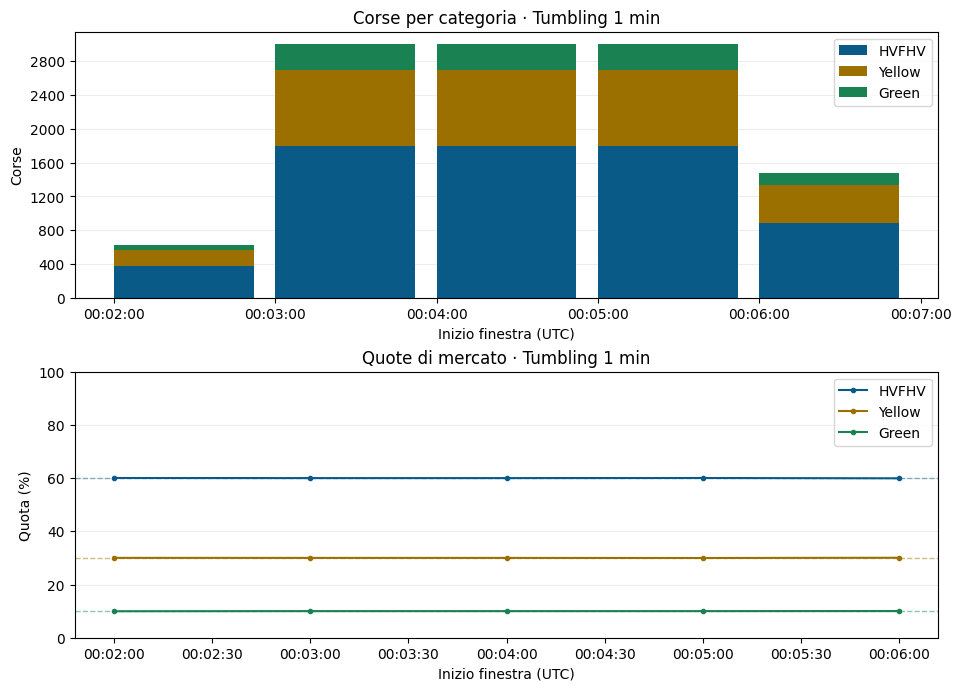

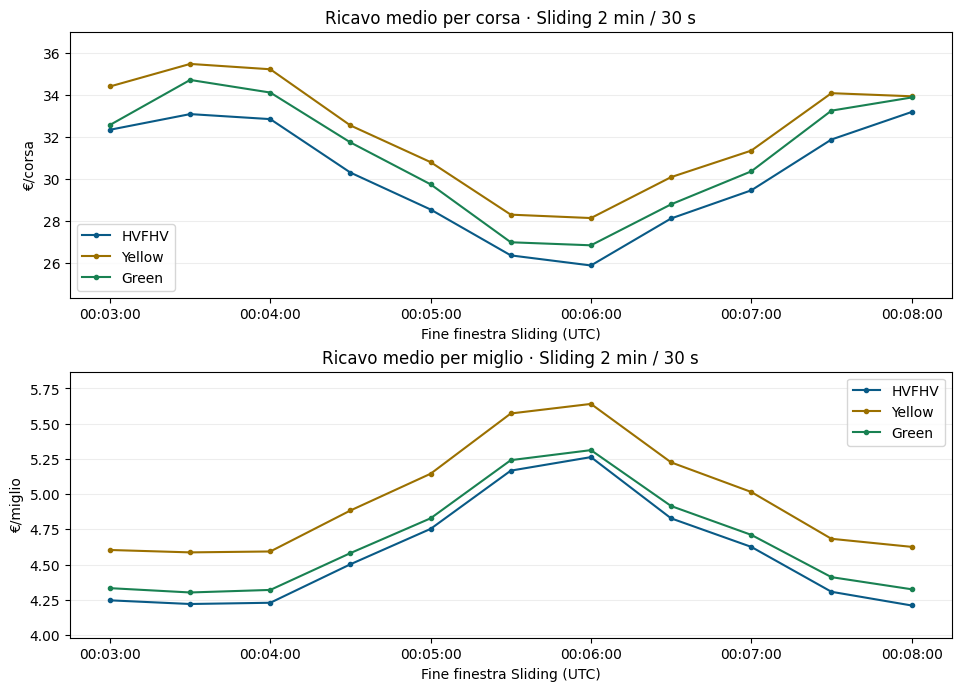

In [4]:
from src.comparison import run_lab

if RUN_MODE == "run":
    spark = spark_session()
    paths, manifest, archived_trips = run_lab(spark, CONFIG, on_update=render_live)

## Esito e modalità demo

La demo usa gli artefatti locali della run. Imposta `INSPECT_HDFS = True` per consultare anche le corse Parquet e il confronto su HDFS. Il riepilogo descrittivo per fase è calcolato in batch sulle corse archiviate.

Le linee tratteggiate nel grafico delle quote indicano i riferimenti 60%, 30% e 10%. I grafici Sliding includono anche le finestre parziali iniziali e finali.

Run 20261126_000244_95675104 · COMPLETE · confronto PASS
Avvio UTC 2026-11-26T00:02:44.693980+00:00 · fine UTC 2026-11-26T00:07:26.583779+00:00


Voce,Valore
Corse target,12000
Corse archiviate,12000
ID distinti,12000
Durata nominale (s),240
Durata effettiva fino alla verifica HDFS (s),246.2
Primo evento UTC,2026-11-26T00:02:47.552000+00:00
Ultimo evento UTC,2026-11-26T00:06:47.532000+00:00
Watermark finale UTC,2026-11-26T00:04:47.532Z
Righe scartate dal watermark (metrica Spark),0
ID duplicati,0


Micro-batch elaborati (per query)


Query,Micro-batch
generator,26
tumbling,27
sliding,27


Tipo,Finestre confrontate,Parziali
tumbling,5,2
sliding,12,8


Categoria,Corse,Quota (%)
HVFHV,7200,60.0000
Green,1200,10.0000
Yellow,3600,30.0000


... (3 outputs left out)

Ricavi per categoria · ultime finestre sliding


window_start,vehicle_type,n,avg_revenue_per_trip_eur,avg_revenue_per_mile_eur
2026-11-26 00:05:30,Green,388,33.4637,4.3909
2026-11-26 00:05:30,HVFHV,2326,32.2906,4.2855
2026-11-26 00:05:30,Yellow,1163,34.2603,4.6660
2026-11-26 00:06:00,Green,238,33.9887,4.3263
2026-11-26 00:06:00,HVFHV,1425,33.3681,4.2137
2026-11-26 00:06:00,Yellow,714,34.2821,4.6207
2026-11-26 00:06:30,Green,88,33.9133,4.3400
2026-11-26 00:06:30,HVFHV,526,33.6336,4.2225
2026-11-26 00:06:30,Yellow,263,34.4559,4.6220


Riepilogo per fase


Fase,Corse,Distanza media (mi),Durata media (min),Minuti medi per miglio,Ricavo medio (€/corsa),Ricavo totale (€)
NORMAL iniziale,3600,7.7763,26.3447,3.3878,33.7557,121520.50
HIGH_TRAFFIC,4800,4.2507,24.9716,5.8747,24.8919,119481.31
NORMAL finale,3600,7.7350,26.2888,3.3987,33.6223,121040.13


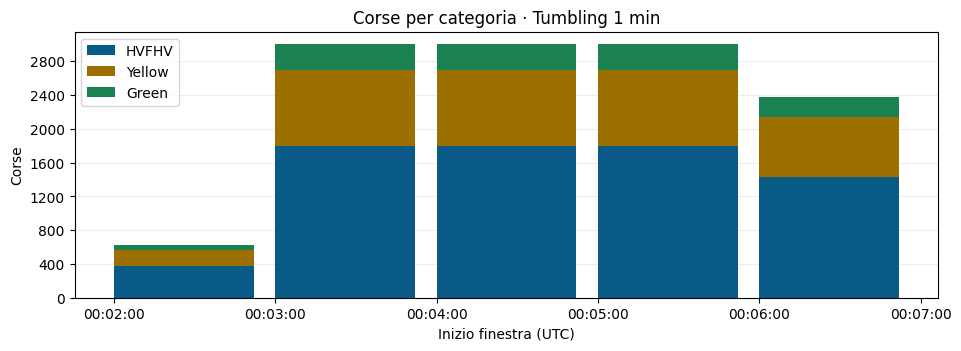

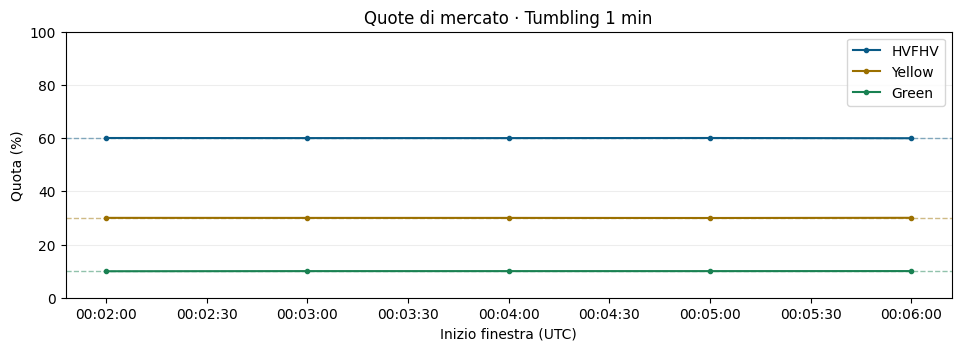

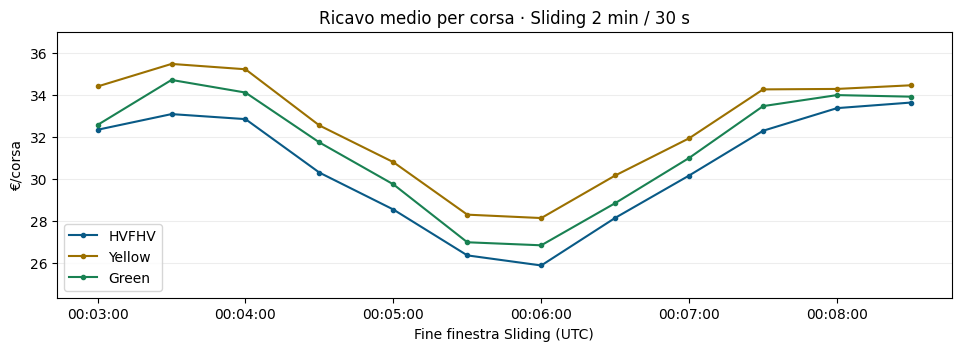

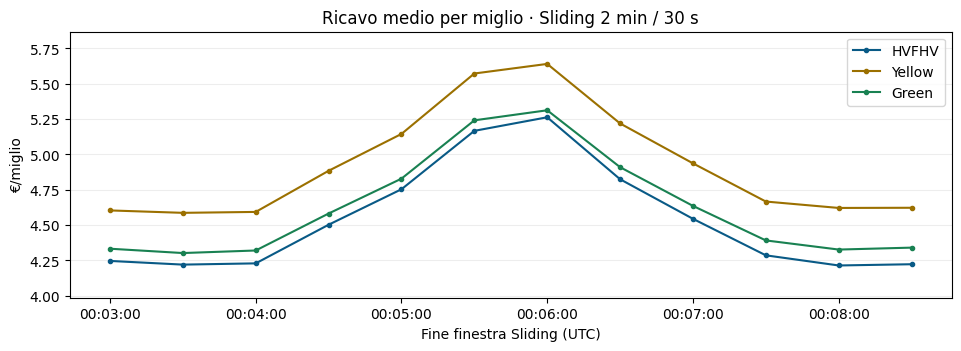

Snapshot tumbling disponibili tumbling_001, tumbling_002, tumbling_003, tumbling_004


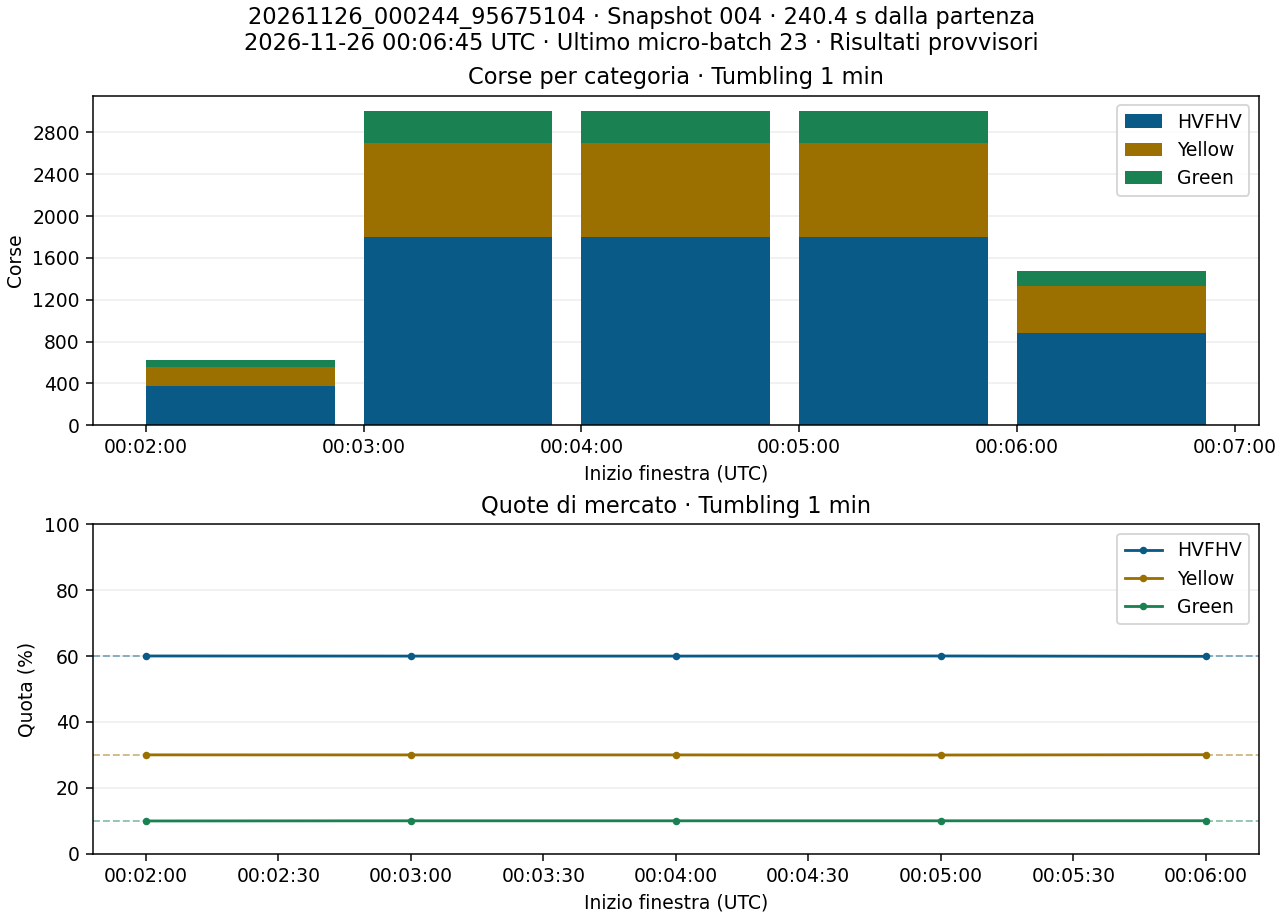

Snapshot sliding disponibili sliding_001, sliding_002


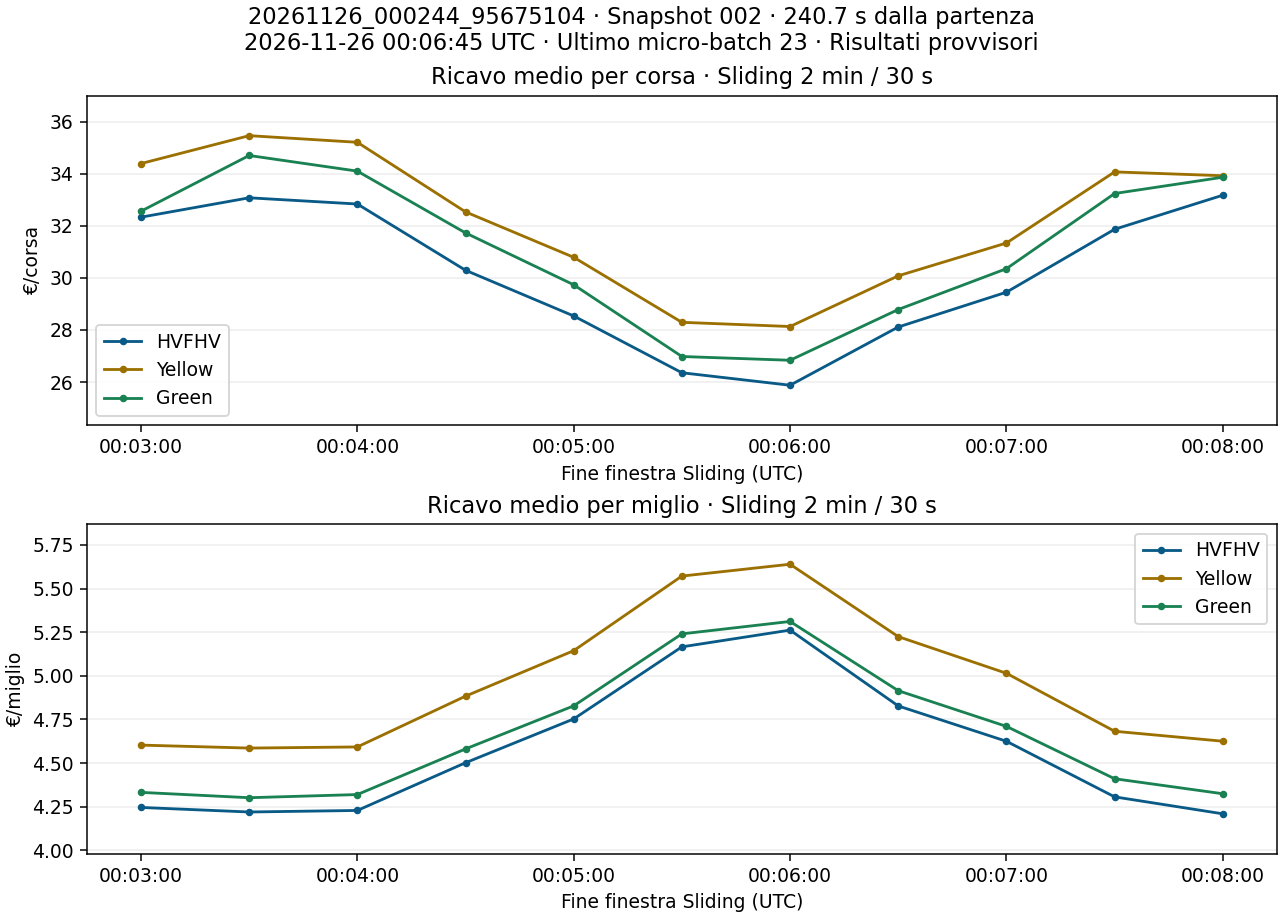

Ultimi micro-batch. Il registro completo è in progress.jsonl.


query,batch_id,trigger_at_utc,observed_at_utc,input_rows,event_max_utc,watermark_utc,rows_dropped_by_watermark
sliding,23,2026-11-26T00:06:40.000Z,2026-11-26T00:06:41.665135+00:00,500,2026-11-26T00:06:29.532Z,2026-11-26T00:04:19.532Z,0
generator,25,2026-11-26T00:06:50.001Z,2026-11-26T00:06:50.676210+00:00,500,,,0
tumbling,24,2026-11-26T00:06:50.001Z,2026-11-26T00:06:51.298663+00:00,500,,,0
sliding,24,2026-11-26T00:06:50.001Z,2026-11-26T00:06:51.303873+00:00,500,2026-11-26T00:06:39.532Z,2026-11-26T00:04:29.532Z,0
tumbling,25,2026-11-26T00:07:00.000Z,2026-11-26T00:07:20.063412+00:00,400,,,0
tumbling,26,2026-11-26T00:07:20.001Z,2026-11-26T00:07:20.063426+00:00,0,,,0
sliding,25,2026-11-26T00:07:00.000Z,2026-11-26T00:07:20.069836+00:00,400,2026-11-26T00:06:47.532Z,2026-11-26T00:04:39.532Z,0
sliding,26,2026-11-26T00:07:10.001Z,2026-11-26T00:07:20.069852+00:00,0,,2026-11-26T00:04:47.532Z,0


Diagnostica · prime chiavi


kind,window_start,window_end,vehicle_type,result,partial_window,metrics_mismatched
sliding,2026-11-26 00:01:00,2026-11-26 00:03:00,Green,PASS,True,
sliding,2026-11-26 00:01:00,2026-11-26 00:03:00,HVFHV,PASS,True,
sliding,2026-11-26 00:01:00,2026-11-26 00:03:00,Yellow,PASS,True,
sliding,2026-11-26 00:01:30,2026-11-26 00:03:30,Green,PASS,True,
sliding,2026-11-26 00:01:30,2026-11-26 00:03:30,HVFHV,PASS,True,
sliding,2026-11-26 00:01:30,2026-11-26 00:03:30,Yellow,PASS,True,
sliding,2026-11-26 00:02:00,2026-11-26 00:04:00,Green,PASS,True,
sliding,2026-11-26 00:02:00,2026-11-26 00:04:00,HVFHV,PASS,True,
sliding,2026-11-26 00:02:00,2026-11-26 00:04:00,Yellow,PASS,True,


Confronto completo: results/20261126_000244_95675104/comparison.csv
Campione di corse dal Parquet
+-------+-----------------------+------------+----------------+--------------+------------------+-----------+
|trip_id|start_time             |vehicle_type|traffic_scenario|distance_miles|duration_minutes  |revenue_eur|
+-------+-----------------------+------------+----------------+--------------+------------------+-----------+
|0      |2026-11-26 00:02:47.552|Green       |NORMAL          |6.714         |25.3              |30.67      |
|1      |2026-11-26 00:02:47.572|Yellow      |NORMAL          |9.183         |27.633333333333333|39.78      |
|2      |2026-11-26 00:02:47.592|Yellow      |NORMAL          |5.747         |21.65             |28.2       |
|3      |2026-11-26 00:02:47.612|Yellow      |NORMAL          |10.604        |35.05             |47.04      |
|4      |2026-11-26 00:02:47.632|HVFHV       |NORMAL          |14.895        |46.55             |57.96      |
|5      |2026-11-26 00

In [5]:
from IPython.display import Image
from pyspark.sql import functions as F
from src.demo import read_csv, read_manifest, read_progress
from src.live import CHART_FILES, final_figures


def preview(rows, columns, limit=9):
    return [
        {
            key: float(row[key]) if key.startswith(("share_", "avg_")) and row.get(key) else row.get(key)
            for key in columns
        }
        for row in rows[:limit]
    ]


if RUN_MODE == "demo":
    paths = RunPaths(selected_run) if selected_run else None
    if paths:
        manifest = read_manifest(paths)
        if INSPECT_HDFS:
            spark = spark_session()
            archived_trips = spark.read.parquet(paths.trips)

if paths is None:
    print('Per generare dati, imposta RUN_MODE = "run" nella configurazione ed esegui tutte le celle.')
else:
    print(f"Run {paths.run_id} · {manifest['status']} · confronto {manifest.get('comparison') or 'non concluso'}")
    print(f"Avvio UTC {manifest['started_at_utc']} · fine UTC {manifest.get('finished_at_utc') or '—'}")
    if manifest.get("error"):
        print(manifest["error"])

    total = manifest.get("trip_count")
    history = read_progress(paths)
    diagnostics = read_csv(paths, "comparison")
    elapsed = manifest.get("generation_duration_seconds")
    watermark = next((row["watermark_utc"] for row in reversed(history)
                      if row["query"] == "sliding" and row["watermark_utc"]), None)
    display(HTML(table_html([{"Voce": key, "Valore": value} for key, value in {
        "Corse target": manifest.get("target_trip_count"),
        "Corse archiviate": total,
        "ID distinti": manifest.get("distinct_ids"),
        "Durata nominale (s)": manifest.get("config", {}).get("duration_seconds"),
        "Durata effettiva fino alla verifica HDFS (s)": f"{elapsed:.1f}" if elapsed is not None else "—",
        "Primo evento UTC": manifest.get("first_event_utc"),
        "Ultimo evento UTC": manifest.get("last_event_utc"),
        "Watermark finale UTC": watermark,
        "Righe scartate dal watermark (metrica Spark)": manifest.get("rows_dropped_by_watermark"),
        "ID duplicati": manifest.get("duplicate_ids"),
        "Appartenenze a finestre Sliding": manifest.get("sliding_memberships"),
    }.items()])))
    if history:
        print("Micro-batch elaborati (per query)")
        display(HTML(table_html([
            {"Query": name, "Micro-batch": len({row["batch_id"] for row in history if row["query"] == name})}
            for name in ("generator", "tumbling", "sliding")
        ])))
    if diagnostics:
        display(HTML(table_html([
            {"Tipo": kind, "Finestre confrontate": len({(r["window_start"], r["window_end"])
                for r in diagnostics if r["kind"] == kind}),
             "Parziali": manifest.get("partial_windows", {}).get(kind, 0)}
            for kind in ("tumbling", "sliding")
        ])))
    if total and manifest.get("category_counts"):
        display(HTML(table_html([
            {"Categoria": name, "Corse": count, "Quota (%)": 100 * count / total}
            for name, count in manifest["category_counts"].items()
        ])))

    if manifest.get("checks"):
        display(HTML(table_html([
            {"Controllo": name, "Esito": "PASS" if ok else "FAIL"}
            for name, ok in manifest["checks"].items()
        ])))
        print("Chiavi per esito:", manifest["comparison_rows"], "· differenze:", manifest["differences"])

    tumbling_rows = read_csv(paths, "streaming_tumbling")
    sliding_rows = read_csv(paths, "streaming_sliding")
    if tumbling_rows:
        print("Quote per categoria · ultime finestre tumbling")
        display(HTML(table_html(preview(tumbling_rows[-5:], (
            "window_start", "n_total", "n_hvfhv", "n_yellow", "n_green",
            "share_hvfhv", "share_yellow", "share_green",
        )))))
    if sliding_rows:
        print("Ricavi per categoria · ultime finestre sliding")
        display(HTML(table_html(preview(sliding_rows[-9:], (
            "window_start", "vehicle_type", "n", "avg_revenue_per_trip_eur", "avg_revenue_per_mile_eur",
        )))))

    scenarios = manifest.get("scenario_summary", [])
    if scenarios:
        labels = {1: "NORMAL iniziale", 2: "HIGH_TRAFFIC", 3: "NORMAL finale"}
        print("Riepilogo per fase")
        display(HTML(table_html([
            {"Fase": labels[phase["phase"]], "Corse": phase["trip_count"],
             "Distanza media (mi)": phase["avg_distance_miles"],
             "Durata media (min)": phase["avg_duration_minutes"],
             "Minuti medi per miglio": phase.get("avg_minutes_per_mile"),
             "Ricavo medio (€/corsa)": phase["avg_revenue_eur"],
             "Ricavo totale (€)": f"{phase['total_revenue_cents'] / 100:.2f}"}
            for phase in scenarios
        ])))
    elif diagnostics:
        print("Riepilogo per fase assente negli artefatti di questa run.")

    final_pngs = [paths.local / "charts" / filename
                  for files in CHART_FILES.values() for filename in files]
    legacy_png = paths.local / "trend.png"
    if sliding_rows or tumbling_rows:
        rendered = set()
        for filename, fig in final_figures(tumbling_rows, sliding_rows):
            rendered.add(filename)
            display(fig)
            plt.close(fig)
        for path in final_pngs:
            if path.name not in rendered and path.is_file():
                display(Image(filename=str(path)))
    elif all(path.is_file() for path in final_pngs):
        for path in final_pngs:
            display(Image(filename=str(path)))
    elif legacy_png.is_file():
        display(Image(filename=str(legacy_png)))

    for kind, number in (("tumbling", TUMBLING_SNAPSHOT), ("sliding", SLIDING_SNAPSHOT)):
        folder = paths.local / "snapshots" / kind
        images = sorted(folder.glob(f"{kind}_*.png"))
        if images:
            print(f"Snapshot {kind} disponibili", ", ".join(path.stem for path in images))
            selected = images[-1] if number is None else folder / f"{kind}_{number:03d}.png"
            if selected.is_file():
                display(Image(filename=str(selected)))
            else:
                print(f"Snapshot richiesto assente: {selected.name}")
    if history:
        print("Ultimi micro-batch. Il registro completo è in progress.jsonl.")
        display(HTML(table_html(preview(history[-8:], (
            "query", "batch_id", "trigger_at_utc", "observed_at_utc",
            "input_rows", "event_max_utc", "watermark_utc", "rows_dropped_by_watermark",
        )))))

    if diagnostics:
        problems = [row for row in diagnostics if row["result"] != "PASS"]
        print("Diagnostica ·", "prime difformità" if problems else "prime chiavi")
        display(HTML(table_html(preview(problems or diagnostics, (
            "kind", "window_start", "window_end", "vehicle_type", "result",
            "partial_window", "metrics_mismatched",
        )))))
        print(f"Confronto completo: results/{paths.run_id}/comparison.csv")

    if RUN_MODE == "run" or INSPECT_HDFS:
        print("Campione di corse dal Parquet")
        scenario_column = ["traffic_scenario"] if "traffic_scenario" in archived_trips.columns else []
        archived_trips.orderBy("trip_id").select(
            "trip_id", "start_time", "vehicle_type", *scenario_column,
            (F.col("distance_milli_miles") / 1000).alias("distance_miles"),
            (F.col("duration_seconds") / 60).alias("duration_minutes"),
            (F.col("revenue_cents") / 100).alias("revenue_eur"),
        ).show(6, truncate=False)
        if RUN_MODE == "demo" and manifest.get("comparison"):
            spark.read.parquet(paths.final("comparison")).groupBy("kind", "result").count().show()

### Conclusioni

Il confronto verifica gli indicatori prodotti dallo streaming sulle stesse corse archiviate e rilette da Spark SQL. L’esito riguarda tutte le chiavi dell’esecuzione, comprese le finestre parziali. In caso di `FAIL`, il CSV diagnostico riporta i valori dei due lati e le metriche discordanti.